# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.

### How to use this notebook
- Run cells top to bottom. Cells starting with `!` run shell commands.
- Change `MODEL` / `MODEL2` below if the model names differ on your installation.
- Fill in the **✍️ Your answer** cells — they feed your final report.

## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [52]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
System  : Linux 6.6.159+


In [53]:
!pip --version

pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)


### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [54]:
!apt-get install -y zstd > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh

>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [55]:
import subprocess, time
server = subprocess.Popen(["ollama", "serve"],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)

In [56]:
!ollama --version

ollama version is 0.40.11


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [57]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
If the exact name differs on your installation, pick a small instruct/chat model suited to your hardware.

In [58]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3.5"   # Model 1
MODEL2 = "gemma3"    # Model 2 (used in the comparison parts)

In [59]:
!ollama pull {MODEL}

In [60]:
!ollama list

NAME              ID              SIZE      MODIFIED               
qwen3.5:latest    56671c2ab938    6.6 GB    Less than a second ago    
gemma3:latest     68ceab7e468a    3.4 GB    8 minutes ago             


### Exercise 4 — Run the model
In the terminal you would use `ollama run qwen3.5`. Here we do the same thing through the API with a helper function.

In [61]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [62]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[49.3s]
Artificial intelligence refers to computer systems designed to simulate human cognitive functions like reasoning and perception. These systems are capable of performing tasks such as learning from experience, solving problems, and recognizing patterns within data. They achieve this capability by using complex algorithms and machine learning models to analyze vast amounts of information. AI is currently utilized in a wide range of applications, including virtual assistants, medical diagnostics, and autonomous vehicles. Ultimately, the technology aims to automate complex processes and augment human productivity across various industries.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[47.8s]
Imagine if you had a super-fast computer friend who could learn how to do things just by watching and listening to people, kind of like a puppy learning tricks in the backyard.

That is basically what Arti

### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

**✍️ Your answer:**

1. **Yes, the answers differ.** An LLM generates text token by token by *sampling* from a probability distribution (temperature > 0), and each prompt sets a different role/audience: the 5-sentence version is compact, the "10-year-old" version uses analogies and simple words, the "professor" version uses technical vocabulary (generalisation, optimisation, representation learning...). Even the same prompt can give different wording from one run to the next.
2. **No.** The request goes to `http://localhost:11434`, i.e. the Ollama server on my own machine. No cloud API is involved.
3. **Inference is performed locally**, by Ollama (llama.cpp engine) on my CPU and/or GPU, using the model weights stored on my disk and loaded into RAM/VRAM.
4. **Nothing changes**: once the model is downloaded, the notebook keeps working with Wi-Fi/Ethernet disabled, because `localhost` does not need Internet. Only `ollama pull` (downloading) requires a connection.

## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [63]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[112.5s]
Hello, students. Please take your seats and let us begin today's lecture on Graph Theory. Today, we will be exploring one of the most fundamental structures in computer science and discrete mathematics: the **Directed Acyclic Graph**, or simply a **DAG**.

Grab your notebooks; here is our structured overview for today.

***

### 1. Definition
A **Directed Acyclic Graph (DAG)** is a specific type of graph that possesses two defining characteristics:

1.  **Directed:** The edges in the graph have directionality, meaning they go from one node to another. This represents a flow, dependency, or causation (denoted as $u \rightarrow v$).
2.  **Acyclic:** There are no cycles within the graph. You cannot start at a vertex, follow a series of edges, and eventually return to the same starting vertex without retracing your steps backwards.

Mathematically, we can represent a DAG as $G = (V, E)$, where $V$ is the set of vertices (nodes) and $E$ is the set of directed edges such that there 

In [64]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[94.7s]
Hello and welcome to class! Today we are going to talk about **DAGs** (pronounced "dags"). It sounds cool, right? Like a secret club. But don't worry—it's just a specific type of map or diagram that shows how things connect.

You’ve probably seen graphs before in geometry. You know the idea of points connected by lines. A DAG is a graph with three very specific rules. Let’s break them down using plain English:

1.  **Graph:** Just means it has nodes (points, like dots) and edges (lines connecting them).
2.  **Directed:** The lines have direction (like one-way streets with arrows pointing from Point A to Point B). This means the relationship is not equal; "A leads to B," not just "A is next to B."
3.  **Acyclic:** This is the tricky part! *Cyclic* means a cycle, or a loop, where you can start at a point and follow the arrows all the way around and end up back at the start (like an infinite loop in code). *Acyclic* simply means **no loops**. Once you move forward, you never come 

### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**✍️ Your answer:**

| Element | Prompt A | Prompt B |
|---|---|---|
| **Role** | University professor | University professor (same) |
| **Context / audience** | none given: the model assumes a general/academic audience | first-year CS student: sets the level of the explanation |
| **Constraints** | 5 mandatory sections | simple language, one example |
| **Output format** | explicit numbered structure (definition, example, adjacency matrix, application, code) | free-form |
| **Specificity** | very specific and verifiable (you can check each item is present) | vaguer: the model chooses what to include |

**Observation:** Prompt A gives a longer, structured, complete and technical answer (with matrix and Python code) that is easy to evaluate. Prompt B gives a shorter, more pedagogical answer adapted to a beginner but without guaranteed content. The **role** sets tone and expertise, the **context** sets the level, the **constraints** limit scope, the **output format** makes the answer predictable and parsable, and **specificity** reduces ambiguity, so the answer is more reproducible and relevant. A good prompt combines all five.

## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [65]:
!ollama list

NAME              ID              SIZE      MODIFIED       
qwen3.5:latest    56671c2ab938    6.6 GB    6 minutes ago     
gemma3:latest     68ceab7e468a    3.4 GB    14 minutes ago    


In [66]:
!ollama show {MODEL}

  Model
    architecture        qwen35             
    parameters          9.0B               
    context length      262144             
    embedding length    4096               
    quantization        Q4_K_M             
    requires            0.30.0             
    renderer            qwen3.5            
    parser              qwen3.5            
    template source     renderer_parser    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          456.01M    
    embedding length    1152       
    dimensions          4096       

  Parameters
    presence_penalty    1.5     
    temperature         1       
    top_k               20      
    top_p               0.95    

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [67]:
!ollama ps

NAME              ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen3.5:latest    56671c2ab938    5.6 GB    100% GPU     4096       llamacpp    4 minutes from now    


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [68]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:latest,6.55,qwen35,9.0B,Q4_K_M
1,gemma3:latest,3.35,gemma3,3.9B,Q4_K_M


Currently loaded in memory:


,name,size_GB,in_VRAM_GB,expires_at
0,qwen3.5:latest,5.61,5.61,2026-10-26T21:47:07.398491052Z


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**✍️ Your answer:**

- **`ollama list`** shows the models **downloaded on disk**: name, ID, size, modification date. **`ollama ps`** shows the models **currently loaded in memory**: name, size in memory, processor split (e.g. 100% GPU or CPU/GPU), and when it will be unloaded (`UNTIL`).
- A **downloaded** model is just a file (weights) sitting on disk; it uses storage but no RAM/VRAM. A **loaded** model has been read into RAM/VRAM and is ready to answer immediately. The first request to a non-loaded model pays a **load time** (`load_duration`); Ollama then keeps it in memory for a few minutes (`keep_alive`, 5 min by default) before unloading it.

## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [69]:
!ollama pull {MODEL2}
!ollama list


NAME              ID              SIZE      MODIFIED               
gemma3:latest     68ceab7e468a    3.4 GB    Less than a second ago    
qwen3.5:latest    56671c2ab938    6.6 GB    7 minutes ago             


### Exercise 7 — Same prompt, different models

In [70]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3.5

```python
import math
from typing import Literal


def is_prime(n: int) -> Literal[True, False]:
    """
    Determines whether a given integer is a prime number using optimized trial division.

    A prime number is a natural number greater than 1 that has no positive divisors 
    other than 1 and itself.

    Parameters:
        n (int): The number to check for primality. Must be an integer.

    Returns:
        bool: True if 'n' is prime, False otherwise.

    Examples:
        >>> is_prime(2)
        True
        >>> is_prime(17)
        True
        >>> is_prime(18)
        False
        >>> is_prime(1)
        False
        >>> is_prime(-5)
        False

    Note:
        - Returns True only for numbers strictly greater than 1.
        - Handles negative numbers, zero, and unity by returning False.
    """
    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False

    limit = int(math.isqrt(n))
    for divisor

Now fill in your evaluation (scores out of 5) and see the table:

In [71]:
scores = {
    MODEL:  {"Response quality /5": None, "Code correctness /5": None},
    MODEL2: {"Response quality /5": None, "Code correctness /5": None},
}  # <- replace None with your scores

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5,23.2,None,None
1,gemma3,20.4,None,None


**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [72]:
def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True

# Paste the model's function below as `candidate` and compare:
# candidate = is_prime
# assert all(candidate(n) == is_prime_reference(n) for n in range(-5, 2000)), "Incorrect!"
# print("✅ candidate matches the reference on 0..2000")

### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**✍️ Your answer:**

> The speed, memory and score numbers come from the table in cell 33 and Part 16. Fill in the bracketed values with *your* measurements.

- **Faster:** [model X] ([..] s, [..] tokens/s). In general the model with fewer parameters / smaller quantised size is faster.
- **Better code:** [model Y], judged with the `assert` test against `is_prime_reference` (correctness) plus presence of type hints, docstring, explanation and complexity O(√n).
- **More memory:** see `ollama ps` / "Loaded size (GB)": [..] GB vs [..] GB. Memory is roughly proportional to parameter count × bits per weight, plus the KV-cache.
- **Choice for programming assistance:** the model that passes the correctness test and respects all requirements at an acceptable latency on my hardware.
- **Is the largest model necessarily the best?** **No.** A larger model is *usually* more capable, but it is slower, needs more memory, and may not fit in RAM/VRAM (which causes swapping and very low speed). Training quality, specialisation (a code-tuned model) and quantisation matter too, so a smaller well-trained model can beat a larger general one on a specific task. The choice should rest on measurements on the target machine.

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [73]:
!pip install -q requests

In [74]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [75]:

import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

Recursion is a programming technique where **a function calls itself** to solve a problem. It breaks a complex problem down into smaller, identical versions of the same problem until it reaches a simple case that can be solved directly.

Here is a comprehensive guide to understanding recursion in Python.

---

### 1. The Core Concept: Two Essential Parts
Every recursive function must have two parts to work correctly:

1.  **Base Case:** The condition where the function stops calling itself and returns a value directly. **This is crucial.** Without it, you get an `Infinite RecursionError`.
2.  **Recursive Case:** The logic where the function calls itself with a modified argument (usually reducing the problem size).

### 2. Classic Example: Factorial
The mathematical factorial of a number $n$ ($n!$) is defined as:
*   $0! = 1$ (Base Case)
*   $n! = n \times (n-1)!$ (Recursive Case)

**Python Code:**
```python
def factorial(n):
    # Base case: stop when n reaches 0 or 1
    if n == 0 or 

In [77]:
%%writefile local_ai_lab/requirements.txt
requests

Writing local_ai_lab/requirements.txt


In [78]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Writing local_ai_lab/README.md


In [79]:
!python local_ai_lab/app.py

python3: can't open file '/content/local_ai_lab/app.py': [Errno 2] No such file or directory


**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [80]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

**Recursion** is a programming technique where a function calls itself in order to solve a problem. It is often used to break down complex problems into smaller, simpler instances of the same problem.

Think of it like **Russian nesting dolls**: you open one doll to reveal a smaller identical doll inside, and you repeat this process until you reach the smallest innermost doll (the "Base Case").

---

### 1. The Two Essential Requirements
For a recursive function to work correctly, you need two things:

1.  **The Recursive Step:** The part where the function calls itself. This breaks the proble ...

{'model': 'qwen3.5', 'created_at': '2026-10-26T21:47:24.390588862Z', 'done': True, 'done_reason': 'stop', 'total_duration': 77972711201, 'load_duration': 990748, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 12, 'prompt_eval_duration': 135795000, 'eval_count': 2069, 'eval_duration': 77684944000, 'wall_s': 77.98469674700027}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [81]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

# chat_loop_stateless()   # <- uncomment to run

In [82]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: At its core, **machine learning (ML)** is a branch of artificial intelligence (AI) that focuses on building systems that can learn from data without being explicitly programmed for every specific task.

Instead of writing strict code to handle every possible scenario, machine learning algorithms identify patterns in data and use those patterns to make predictions or decisions.

### How It Works
Think of it like teaching a child:
*   **Traditional Programming:** You write a set of rules (e.g., "I ...

You: Explain reinforcement learning.
AI: **Reinforcement Learning (RL)** is a type of artificial intelligence where an agent learns how to behave by interacting with an environment and receiving feedback in the form of rewards or punishments.

Unlike supervised learning (where a model learns from labeled data, like photos of cats vs. dogs), reinforcement learning teaches an algorithm **through trial and error**.

Here is a breakdown of how it works, the k

## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [83]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

# chat_loop_memory()   # <- uncomment for interactive use

In [84]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Hello Ahmed! It's nice to meet you. How can I help you today? 

You: What is my name?
AI : Your name is Ahmed! It's nice to know you. Is there anything specific you'd like to talk about or need help with? 



In [85]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Hello Ahmed! It's nice to meet you. How can I help you today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**✍️ Your answer:**

**The LLM itself does not remember anything.** The model is stateless: its weights do not change between calls. The "memory" is implemented by the **application**: the `history` list stores every `User:` / `Assistant:` turn and the whole conversation is **re-sent in the prompt** at each call (see the printed prompt: it contains "User: My name is Ahmed."). The model simply reads the name in its context. Consequences: the history consumes tokens (cost/latency grow with each turn), it is limited by the **context window**, and if the application does not send it, the model forgets.

---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [86]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Your name is Ahmed.


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [87]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[50.7s]
### Senior Java Developer Review: `Calculator.divide()` Method

#### 1. Potential Problems

| Issue | Description | Severity |
|-------|-------------|----------|
| Division by zero | No check for `b == 0`; triggers `ArithmeticException` | 🔴 Critical |
| No input validation | Allows invalid arguments without safeguards | 🟠 High |
| Use of `int` division | Truncates decimal results; loses precision | 🟡 Medium |
| No exception handling or documentation | Makes code difficult to maintain and use | 🟡 Medium |
| Silent truncation behavior | May lead to logic errors downstream | 🟡 Low-Medium |

#### 2. Runtime Errors

- `ArithmeticException: / by zero` — triggered when dividing by zero.
  
Example:
```java
Calculator calc = new Calculator();
int result = calc.divide(10, 0); // Throws ArithmeticException
```

#### 3. Improvements

| Improvement | Benefit | Priority |
|------------|---------|----------|
| Validate divisor | Prevent runtime crash | 🟣 High |
| Use `double` or `BigDecimal`

In [88]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[45.7s]
The bug is in the `setAge` method: **Variable Shadowing.**

### The Problem

In this line:
```java
public void setAge(int age) {
    age = age; // ❌ This assigns the parameter to itself
}
```

Inside the method scope, the variable `age` refers to the **method parameter**, not the instance field `this.age`. Consequently, this assignment updates the local variable (which does nothing useful since they are the same value), but never updates the actual `Student` object's state. The instance field `age` remains unassigned (defaulting to 0).

### The Fix

You must explicitly reference the instance field using `this.` to disambiguate from the parameter variable.

Here is the corrected class with improved best practices (validation + getter):

```java
public class Student {

    private String name;
    private int age; // Default initialization is 0 in Java, but we'll validate setter

    public Student(String name) {
        this.name = name;
        // Optional: Consider passing age

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [89]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[2.5s]
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "High",
  "recommendation": "Immediate intervention required; grade is below typical passing threshold despite low absences."
}


In [90]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'High', 'recommendation': 'Immediate intervention required; grade is below typical passing threshold despite low absences.'}


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [91]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "high",
  "recommendation": "Immediate intervention required due to severe academic underachievement (Grade 15.5 out of 20) despite minimal absences (2); student may need personalized study support, mentorship, or counseling to address motivation and study skills."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

**✍️ Your answer:**

Applications consume LLM output with **code**, not with human eyes. Free text (extra sentences, ```json fences, missing keys, `"15.5"` instead of `15.5`, an invented value like `"risk": "moderate"`) makes `json.loads` fail or breaks business logic. Structured output with a **JSON Schema** (`format=schema`) constrains generation so the result is always valid JSON with the right keys, types and allowed values (`enum`). This brings **reliability** (no fragile regex parsing), **type safety**, **easy integration** (database, API, UI), **testability/validation**, and fewer retries. It makes the LLM behave like a dependable software component.

## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [95]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [96]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [97]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[0.8s]
Reinforcement learning learns through interaction with an environment using rewards and penalties.

[0.3s]
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

**✍️ Your observation:**

For the question inside the document ("What is reinforcement learning?"), the model answers using the text (learning through interaction with an environment, with rewards and penalties). For "What is quantum computing?" the instruction makes it answer *"Information not available."* instead of using its training knowledge, so the answer is **grounded** in the supplied document, which limits hallucinations. This is not 100% guaranteed: a small model may sometimes ignore the instruction and answer from its own knowledge, which is why prompt wording, temperature and testing on several runs matter. [Note here whether it respected the instruction every time in *your* runs.]

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [98]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['deep_learning.txt',
 'machine_learning.txt',
 'ai.txt',
 'reinforcement_learning.txt',
 'course.txt']

In [99]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [100]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
  (0.9s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 8.42789552798877)]
  A: GPUs
  (0.4s)

Q: What is supervised learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Supervised learning uses labelled data.
  (0.6s)

Q: Who won the 2018 World Cup?
  retrieved: []
  A: Information not available.
  (0.4s)



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [101]:
EMBED_MODEL = "nomic-embed-text"
# !ollama pull {EMBED_MODEL}      # <- uncomment once

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

# print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [102]:
VISION_MODEL = MODEL2   # change to a vision-capable model you have installed
IMAGE_PATH = "image.jpg"  # put an image next to the notebook

In [103]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

⚠️ Put an image named 'image.jpg' next to this notebook, then re-run.


### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

**✍️ Your answer:**

- **LLM vs multimodal model:** a classic LLM only takes **text** as input (and produces text). A multimodal model also accepts other modalities (images, sometimes audio/video) through a **vision encoder** whose embeddings are projected into the same space as text tokens.
- **Additional information received:** the image, as base64 in the `images` field, converted into visual tokens/embeddings (pixels, colours, shapes, layout and visible text) in addition to the text prompt.
- **Local applications:** document analysis and **OCR** of confidential documents, invoices and forms, industrial **inspection** (defects), education (explaining diagrams, handwritten work), **medical-image preprocessing** (without sending patient data to the cloud), accessibility (image description), video surveillance analysis. Local execution is valuable where images are **sensitive**.

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [104]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)

In [105]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Writing local-ai-web/app.py


In [106]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

In [107]:
import subprocess, sys, time
web = subprocess.Popen([sys.executable, "app.py"], cwd="local-ai-web",
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(4)

In [108]:
from google.colab import output
output.serve_kernel_port_as_window(5000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [109]:
!pip install -q psutil

In [110]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [111]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = None   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5,6.55,5.61,5.61,30.07,56.22,646,24.99,20.1,None
1,gemma3,3.35,2.88,2.88,4.68,19.27,825,57.27,23.2,None


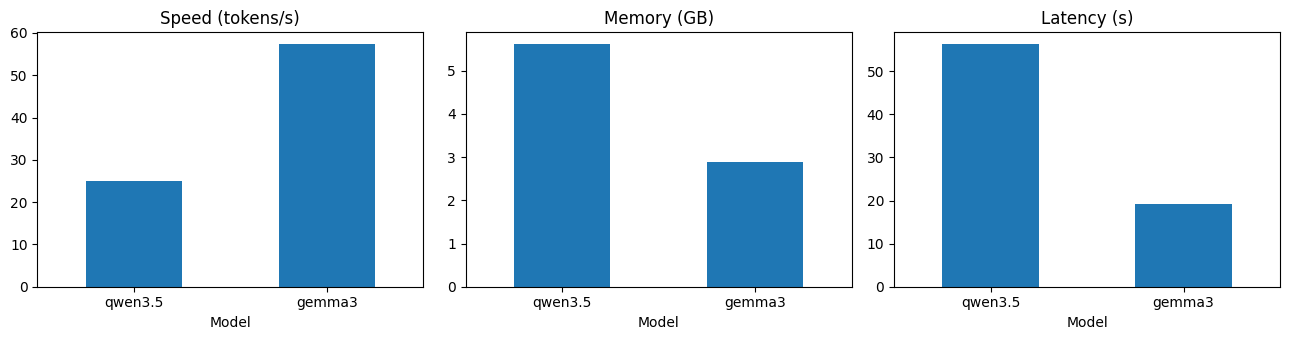

In [112]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

**✍️ Your discussion:**

> Replace the bracketed values with the numbers from `bench_df` (cell 89).

| Model | Loaded size (GB) | Tokens/s | Response time (s) | Quality /5 |
|---|---|---|---|---|
| qwen3.5 | [..] | [..] | [..] | [..] |
| gemma3 | [..] | [..] | [..] | [..] |

Larger models generally give better quality (reasoning, code, instruction following) but need more memory (≈ parameters × bits per weight), generate fewer tokens/s (each token requires reading all the weights, so speed is **memory-bandwidth-bound**) and need stronger hardware. If the model does not fully fit in VRAM, layers are offloaded to CPU/RAM and speed drops sharply. My measurements show that [model X] is [..]× faster and uses [..] GB less memory, while the quality difference is [small/large]. Conclusion: for this machine I would choose [..], because the best model is the one that gives *sufficient* quality at *acceptable* latency within the hardware limits, which public benchmark rankings cannot tell me.

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [113]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# copy shared modules and documents into the deliverable layout
shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [114]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [115]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [116]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [117]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [118]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

Q: What is reinforcement learning?
A: Reinforcement learning is a branch of artificial intelligence where an agent learns through interaction with an environment using rewards and penalties. It involves observing a state, choosing an action, receiving a reward, and aims to learn a policy that maximizes cumulative reward. Common algorithms include Q-learning and policy gradients.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'reinforcement_learning.txt', 'score': 1.02}] · 2.45s · 29.9 tok/s

Q: And how is it different from supervised learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties, whereas supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression).
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'machine_learning.txt', 'score': 1.06}] · 1.66s · 29.1 tok/s

Q: Summarize deep learning
A: {'difficulty': 'easy', 'key_points': ['Artificial neural networks wi

In [119]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

In [120]:
from google.colab import output
output.serve_kernel_port_as_window(5001)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [121]:
print("Code de sortie :", server.poll())   # None = il tourne, un nombre = il s'est arrêté

Code de sortie : -15


In [122]:
import requests
try:
    print(requests.get("http://127.0.0.1:5001/", timeout=5).status_code)
except Exception as e:
    print("Pas de serveur :", e)

Pas de serveur : HTTPConnectionPool(host='127.0.0.1', port=5001): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x793d822bf790>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [123]:
print("Code de sortie :", server.poll())
print(server.stdout.read(3000))

Code de sortie : -15
 * Serving Flask app 'app'
 * Debug mode: off
 * Running on http://127.0.0.1:5001
Press CTRL+C to quit
127.0.0.1 - - [26/Oct/2026 21:56:38] "POST /ask HTTP/1.1" 200 -
127.0.0.1 - - [26/Oct/2026 21:56:40] "POST /ask HTTP/1.1" 200 -
127.0.0.1 - - [26/Oct/2026 21:56:45] "POST /ask HTTP/1.1" 200 -
127.0.0.1 - - [26/Oct/2026 21:56:45] "POST /ask HTTP/1.1" 200 -



In [124]:
import subprocess, sys, time, os
env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(5)
print("Code de sortie :", server.poll())   # doit afficher None

Code de sortie : None


In [125]:
from google.colab import output
output.serve_kernel_port_as_window(5001)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

## Part 18 — Questions for the Report
Answer each question in your own words (use your measurements from Parts 6 and 16 for Q13–Q14).

**Q1.** What is Local AI?

**Local AI** means running AI models (here LLMs) **on your own hardware** (laptop, workstation, on-premise server) instead of calling a remote cloud service. Weights, prompts and responses stay on the machine, so the system works offline, with full control over data and without per-token fees.

**Q2.** Difference between a Cloud LLM and a Local LLM?

A **cloud LLM** (GPT, Gemini, Claude...) runs in the provider's data centres and is accessed over the Internet through a paid API: very large and capable models, no hardware to manage, but data leaves your machine, there is a recurring cost, a dependency on connectivity and the vendor, and rate limits. A **local LLM** runs on your own machine: private, offline, no per-token cost, customisable, but limited by your hardware (smaller/quantised models, slower) and you handle installation, updates and security.

**Q3.** What role does Ollama play?

Ollama is a **local runtime and model manager** built around llama.cpp. It downloads and stores models (`pull`, `list`), loads them into RAM/VRAM, runs inference on CPU/GPU, handles quantised formats and chat templates, and exposes a simple **REST API** on `localhost:11434` (`/api/generate`, `/api/chat`, `/api/embed`, `/api/tags`, `/api/ps`). The same model can therefore be used from the terminal, Python, a web app, or Open WebUI.

**Q4.** What is model quantization?

**Quantization** reduces the numerical precision of the model weights (e.g. from 16-bit floats to 8, 5 or 4-bit integers, like Q4_K_M). The model becomes much **smaller and faster** and uses less memory, at the price of a slight loss in accuracy. It is what makes models with billions of parameters run on a laptop.

**Q5.** Why does model size affect memory consumption?

Memory is dominated by the weights: **memory ≈ number of parameters × bits per weight / 8**. For instance, 7B parameters at 16 bits ≈ 14 GB, and at 4 bits ≈ 3.5 GB. On top of that come the **KV-cache** (grows with context length) and runtime buffers. More parameters therefore means more RAM/VRAM required; if it does not fit, the system offloads to the CPU or swaps and becomes very slow.

**Q6.** Why can a smaller model sometimes be preferable?

A smaller model is preferable when: RAM/VRAM is limited; **low latency** or high throughput is needed; the task is simple or narrow (classification, extraction, summarisation, RAG with good context); it runs on edge/embedded devices; or energy and cost matter. It loads faster, answers faster and several instances can run in parallel. With good prompting, structured output or RAG it is often "good enough".

**Q7.** Advantages of local inference?

**Advantages of local inference:** privacy and data sovereignty (nothing leaves the machine); offline operation; no per-token cost; low network latency; full control over the model, version and parameters (reproducibility); no vendor lock-in or rate limits; possibility to customise or fine-tune; compliance with regulations (GDPR, confidential research data).

**Q8.** Disadvantages of local inference?

**Disadvantages:** less capable models than frontier cloud ones; hardware requirements and cost (RAM, GPU); slower generation on CPU; the user manages installation, updates, monitoring and scaling; energy consumption on the local machine; limited context length; and the user is responsible for security (access control, patching).

**Q9.** Explain the architecture of your Python application.

The final app is a **Flask** web application: `Browser → Flask (/ask) → Retriever (rag.py, TF-IDF over documents/) → builds a prompt (system + history + CONTEXT + question) → Ollama /api/chat (localhost:11434) → local LLM → answer`. Flask keeps the **conversation history** (last 6 turns), can request a **structured JSON** answer with a schema, measures the **response time**, tokens and tokens/s, and returns the answer and its sources to the browser. Everything runs on `127.0.0.1`, so it is 100% local.

**Q10.** Explain the role of the REST API.

The REST API is the **interface between the application and the model**. Ollama exposes HTTP endpoints; the Python client sends a JSON request (model, prompt/messages, options, format) with `POST` and receives a JSON response. It decouples the client from the inference engine: any language or tool (Python, Java, curl, browser, Open WebUI) can use the same model, and the application does not need to know how inference works.

**Q11.** What is RAG?

**RAG (Retrieval-Augmented Generation)** combines a **retriever** and a **generator**. The system first searches a document base for the passages relevant to the question (keywords/TF-IDF or embeddings), then inserts them as context into the LLM prompt. The model answers from this context. Benefits: up-to-date and private knowledge without retraining, fewer hallucinations, traceable sources, and "Information not available" when nothing relevant is found.

**Q12.** Difference between an LLM and a multimodal LLM?

A classic **LLM** processes only text. A **multimodal LLM** can process several modalities (text + images, sometimes audio or video) thanks to an encoder that converts the image into embeddings the language model can read. It can describe images, read text in images (OCR), analyse charts and answer visual questions.

**Q13.** Compare two local models experimentally.

[Insert the table from Part 16 (`bench_df`) and from cell 33.]

Method: same prompt, cold start (`keep_alive: 0` before each run), measuring load time, response time, tokens generated, tokens/s, loaded size and VRAM. Result: [model X] was [faster/slower] ([..] vs [..] tokens/s) and used [..] GB vs [..] GB; quality was [..]/5 vs [..]/5 (code tested with the reference assertion). Conclusion: [which one is better for which use, and why].

**Q14.** Which model would you deploy on a computer with limited RAM? Explain.

I would deploy a **small quantised model** (about 1–4B parameters at 4-bit, such as a small Gemma/Qwen/Llama variant), i.e. under ~2–3 GB, for a machine with 8 GB of RAM or less. It fits entirely in memory, leaves room for the OS and the KV-cache, avoids swapping, and gives acceptable speed on CPU. I would combine it with **RAG** and structured output to compensate for its limited knowledge, and I would limit the context length to save memory. [Confirm with your measured "Loaded size (GB)".]

**Q15.** What security risks exist when exposing a local LLM server to a network?

By default Ollama has **no authentication**, and setting `OLLAMA_HOST=0.0.0.0` exposes it to the whole network. Risks: **unauthorised use of my compute** (anyone can run prompts and saturate CPU/GPU, causing denial of service); **model management abuse** (pull/delete/create models through the API); **data exposure** (prompts, responses, loaded documents, system prompts) and traffic sniffed in plain HTTP; **prompt injection** through documents or web pages ingested by RAG, which can make the model leak data or follow malicious instructions (especially if it has tools); exposure of vulnerabilities in an unpatched server; and no audit or rate limiting. **Mitigations:** keep it bound to `127.0.0.1`; use a **firewall**/VPN; put a **reverse proxy** (nginx/Caddy) in front with **authentication (API key/OAuth) and TLS**, rate limiting and logging; keep Ollama updated; treat retrieved documents as untrusted input; and do not expose Flask in debug mode.

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [130]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))

✅ LocalAI_Lab/report.pdf
✅ LocalAI_Lab/README.md
✅ LocalAI_Lab/source/app.py
✅ LocalAI_Lab/source/chatbot.py
✅ LocalAI_Lab/source/rag.py
✅ LocalAI_Lab/source/benchmark.py
✅ LocalAI_Lab/screenshots/01_installation.png
✅ LocalAI_Lab/screenshots/02_model.png
✅ LocalAI_Lab/screenshots/03_chatbot.png
✅ LocalAI_Lab/screenshots/04_python.png
✅ LocalAI_Lab/screenshots/05_rag.png
✅ LocalAI_Lab/screenshots/06_webapp.png

Documents: ['ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']


In [131]:
!zip -r LocalAI_Lab.zip LocalAI_Lab

  adding: LocalAI_Lab/ (stored 0%)
  adding: LocalAI_Lab/README.md (deflated 31%)
  adding: LocalAI_Lab/.ipynb_checkpoints/ (stored 0%)
  adding: LocalAI_Lab/screenshots/ (stored 0%)
  adding: LocalAI_Lab/screenshots/03_chatbot.png (deflated 12%)
  adding: LocalAI_Lab/screenshots/01_installation.png (deflated 10%)
  adding: LocalAI_Lab/screenshots/00_webapp.png (deflated 15%)
  adding: LocalAI_Lab/screenshots/05_rag.png (deflated 8%)
  adding: LocalAI_Lab/screenshots/04_python.png (deflated 14%)
  adding: LocalAI_Lab/screenshots/02_model.png (deflated 12%)
  adding: LocalAI_Lab/screenshots/06_webapp.png (deflated 12%)
  adding: LocalAI_Lab/source/ (stored 0%)
  adding: LocalAI_Lab/source/app.py (deflated 55%)
  adding: LocalAI_Lab/source/__pycache__/ (stored 0%)
  adding: LocalAI_Lab/source/__pycache__/rag.cpython-313.pyc (deflated 41%)
  adding: LocalAI_Lab/source/rag.py (deflated 50%)
  adding: LocalAI_Lab/source/chatbot.py (deflated 45%)
  adding: LocalAI_Lab/source/templates/ (stor